# Mini Project 1 · Group A
## Detection and Analysis of Performance Loss in a PLC-Controlled Production System Using Unsupervised Learning
### Stage 2: Operational Hypothesis Testing (H1–H4) & Safety Stop Analysis

**Lead Author:** Lakshmi Narayana Reddy Mandi  
**Team Members:** Neeraj Bhuma, Lakshmi Narayana Reddy Mandi, Naga Sai Priyanka Truvidhula  
**Supervisor:** Prof. Felix Georg Müller  
**Institution:** Hochschule Albstadt-Sigmaringen (November 2026)

In [18]:
import pandas as pd  # for tables and time handling

merged_path = (  # where the merged CSV is stored
    ""
    "output directory/merged_85ms.csv"
)

merged = pd.read_csv(merged_path)  # read the table from the CSV
merged["utc_time"] = pd.to_datetime(  # turn text into real UTC times
    merged["utc_time"], utc=True, format="ISO8601"
)

helper_cols = [  # the 7 timing columns, not process signals
    "utc_time", "timestamp_beckhoff", "beck_time", "beck_age_ms",
    "timestamp_siemens", "sie_time", "sie_age_ms",
]
signal_cols = [  # all other columns are process signals
    c for c in merged.columns if c not in helper_cols
]

merged["t_s"] = (  # seconds since the first row, for easy durations
    merged["utc_time"] - merged["utc_time"].iloc[0]
).dt.total_seconds()

print("Rows:", len(merged))  # how many rows the table has
print("Signal columns:", len(signal_cols))  # how many signals
print("Time span in seconds:", round(merged["t_s"].iloc[-1], 3))

Rows: 5945
Signal columns: 195
Time span in seconds: 505.24


/var/folders/w_/7nrlrf2s6639mshlpwps2wb00000gn/T/ipykernel_77952/4290417408.py:21: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  merged["t_s"] = (  # seconds since the first row, for easy durations


**What:**
- Load the cleaned merged table merged_85.csv (85 ms grid, 5945 rows)
- Turn utc_time back into real UTC times
- Separate the signal columns from the 7 helper columns
- Add t_s, the time in seconds since the first row

**Why:**
- The file is read fresh, so this notebook runs on its own
- Reading a CSV gives text, so the times must be parsed
- format="ISO8601" accepts times with and without fractions
- t_s makes all later durations simple subtractions in seconds

**Output:**
- Rows: 5945
- Signal columns: 195
- Time span in seconds: 505.24
- A PerformanceWarning may appear, it only concerns speed

**Next:** build the pulse detector and find all ON-periods

In [19]:

def pulses(df, column):  # find all complete ON-periods of one signal
    on = df[column].eq(1).astype(int)  # 1 while ON, else 0
    changes = on.diff()  # +1 = rising edge, -1 = falling edge
    starts = df.loc[changes.eq(1), "t_s"]  # times of the rising edges
    ends = df.loc[changes.eq(-1), "t_s"]  # times of the falling edges

    periods = []  # collects the (start, end) pairs
    for start in starts:  # go through every rising edge
        later_ends = ends[ends > start]  # falling edges after this start
        if not later_ends.empty:  # only if the period has an end
            periods.append((start, later_ends.iloc[0]))  # first end counts
    return periods  # list of complete ON-periods


# Output selection from the reference notebook.
not_steps = (  # Siemens output prefixes we leave out
    "A200", "A201", "A6.", "A0.1", "A1.5", "A1.6", "A4.1",
)
long_copies = ("_horizontal_", "_vertical_", "_cantilever_")  # skipped

output_signals = []  # (PLC, signal) pairs we treat as step outputs
for column in signal_cols:  # check every signal column
    if column.startswith("A") and not column.startswith(not_steps):
        output_signals.append(("Siemens", column))  # Siemens output
    elif ".Q" in column and not any(
        text in column for text in long_copies  # skip long-named copies
    ):
        output_signals.append(("Beckhoff", column))  # Beckhoff output

rows = []  # one row per ON-period
edge_signals = []  # signals that are ON in the first or last row

for plc, column in output_signals:  # every selected output
    for start, end in pulses(merged, column):  # its complete ON-periods
        rows.append((plc, column, start, end, end - start))  # + duration

    # Signals that are ON at the first or last row.
    if merged[column].iloc[0] == 1 or merged[column].iloc[-1] == 1:
        edge_signals.append(column)  # its boundary period is incomplete

steps = pd.DataFrame(  # table of all complete ON-periods
    rows,
    columns=["plc", "signal", "start_s", "end_s", "dur_s"],
)

print("Selected output signals:", len(output_signals))  # expect 32
print("Complete ON-periods:", len(steps))  # expect 497
print("Signals with excluded boundary periods:", edge_signals)
print(steps.head(10).to_string(index=False))  # first 10 periods

Selected output signals: 32
Complete ON-periods: 497
Signals with excluded boundary periods: ['WH.Q7_cantForw', 'WH.Q8_cantBack']
     plc        signal  start_s   end_s  dur_s
Beckhoff WH.Q3_horRack   34.000  37.060  3.060
Beckhoff WH.Q3_horRack   88.315  90.015  1.700
Beckhoff WH.Q3_horRack   98.090 100.640  2.550
Beckhoff WH.Q3_horRack  144.330 148.665  4.335
Beckhoff WH.Q3_horRack  199.495 202.640  3.145
Beckhoff WH.Q3_horRack  252.025 265.625 13.600
Beckhoff WH.Q3_horRack  272.765 275.400  2.635
Beckhoff WH.Q3_horRack  324.870 329.205  4.335
Beckhoff WH.Q3_horRack  384.030 387.090  3.060
Beckhoff WH.Q3_horRack  444.125 445.910  1.785


**What:**
- Define pulses(), which finds every complete ON-period of a signal (rising edge 0 -> 1 until the next falling edge 1 -> 0)
- Select the output signals we treat as machine steps: Siemens outputs (names starting with A, except 7 excluded prefixes) and Beckhoff .Q outputs (except the long-named copies)
- Build the table steps with one row per ON-period: PLC, signal, start, end and duration in seconds

**Why:**
- One ON-period of an output is one activation of a step, so its duration is what we compare in H1
- We take the output selection from our earlier reference notebook, so the numbers stay comparable
- A period that is already ON in the first row or still ON in the last row has no complete start or end. We do not count it and we list those signals instead of hiding them

**Output:**
- Selected output signals: 32
- Complete ON-periods: 497
- Signals with excluded boundary periods: WH.Q7_cantForw and WH.Q8_cantBack
- The first 10 rows, for example WH.Q3_horRack 34.000 -> 37.060 s (3.060 s)

**Next:** 
- Build the baseline per signal and flag unusually long activations (H1)

In [20]:
slow_factor = 1.25  # at least 25% above the signal median
min_extra_s = 2.0  # and at least 2 s longer than the median
min_repeats = 5  # minimum number of activations per signal
min_median_s = 0.25  # minimum median duration of a signal

baseline = steps.groupby(["plc", "signal"])["dur_s"].agg(  # per signal
    repetitions="count",  # number of activations
    median_s="median",  # usual duration
)

baseline = baseline[  # keep only signals with a usable baseline
    (baseline["repetitions"] >= min_repeats)  # enough repetitions
    & (baseline["median_s"] >= min_median_s)  # long enough pulses
]

compared_steps = steps.merge(  # add the baseline to every activation
    baseline,
    left_on=["plc", "signal"],  # key in the activation table
    right_index=True,  # key is the index of the baseline
    how="inner",  # only activations of signals with a baseline
)

compared_steps["extra_s"] = (  # seconds above the median
    compared_steps["dur_s"] - compared_steps["median_s"]
)
compared_steps["slow"] = (  # True if both conditions hold
    (compared_steps["dur_s"] >= slow_factor * compared_steps["median_s"])
    & (compared_steps["extra_s"] >= min_extra_s)
)

slow_steps = compared_steps[compared_steps["slow"]].copy()  # flagged only

print("Signals with a usable baseline:", len(baseline))  # expect 28
print("Activations compared:", len(compared_steps))  # expect 487
print("Flagged activations:", len(slow_steps))  # expect 13
print(
    slow_steps.sort_values("start_s")[  # in time order
        ["plc", "signal", "start_s", "dur_s", "median_s", "extra_s"]
    ].round(3).to_string(index=False)
)

Signals with a usable baseline: 28
Activations compared: 487
Flagged activations: 13
     plc             signal  start_s  dur_s  median_s  extra_s
Beckhoff      WH.Q4_horBelt  108.630  4.505     1.700    2.805
Beckhoff      WH.Q3_horRack  252.025 13.600     3.102   10.498
 Siemens               A1.7  253.725 18.105     9.265    8.840
Beckhoff      WH.Q4_horBelt  283.050  4.335     1.700    2.635
Beckhoff  WH.Q1_beltForward  290.870  7.820     0.850    6.970
Beckhoff WH.Q2_beltBackward  314.500  6.715     0.595    6.120
Beckhoff  WH.Q1_beltForward  350.455  9.605     0.850    8.755
 Siemens               A0.7  362.695  7.990     5.780    2.210
 Siemens               A1.0  384.710  5.015     1.020    3.995
Beckhoff     WH.Q7_cantForw  387.090 13.430     3.060   10.370
Beckhoff      WH.Q3_horRack  452.625 10.285     3.102    7.183
Beckhoff     WH.Q8_cantBack  468.095  7.990     3.145    4.845
Beckhoff      WH.Q4_horBelt  477.785  4.250     1.700    2.550


**What:**
- H1: find activations that are unusually long compared with the usual duration of the same signal
- Baseline per signal: number of repetitions and median duration
- An activation is flagged when it is at least 25% longer than the median (slow_factor 1.25) and at least 2.0 s longer (min_extra_s)

**Why:**
- We compare every signal only with itself, because steps differ in normal length
- A baseline needs at least 5 repetitions (min_repeats) and a median of at least 0.25 s (min_median_s), otherwise it is too weak or too short to judge
- Both conditions together, relative and absolute, avoid flagging tiny differences on very short pulses
- These four values are our chosen screening rules, not proven limits, so we call the flagged activations candidates

**Output:**
- Signals with a usable baseline: 28
- Activations compared: 487
- Flagged activations: 13 (10 Beckhoff, 3 Siemens)
- Largest: WH.Q3_horRack at 252.025 s, 13.600 s against a median of 3.102 s (10.498 s extra); WH.Q7_cantForw at 387.090 s, 13.430 s against 3.060 s (10.370 s extra)
- Smallest extra: A0.7 at 362.695 s with 2.210 s extra

**Next:** 
- Detect the stop indicators (curtain and screen) and check whether they overlap the flagged activations

In [21]:
stop_data = merged[["t_s"]].copy()  # new table, starts with time only
stop_data["curtain_off"] = merged["A201.0"].eq(0)  # curtain indicator
stop_data["screen_off"] = merged["Visual.start"].eq(0)  # screen indicator

stop_rows = []  # one row per indicator interval
for signal, label in [  # both indicators with their report labels
    ("curtain_off", "Curtain interruption"),
    ("screen_off", "Screen-pause indicator"),
]:
    for start, end in pulses(stop_data, signal):  # complete intervals
        stop_rows.append((label, start, end))  # keep label and times

stop_events = pd.DataFrame(  # table of the intervals
    stop_rows, columns=["indicator", "start_s", "end_s"]
).sort_values("start_s")  # in time order

# Combine overlapping intervals for duration calculations.
combined = []  # merged intervals as [start, end]
for row in stop_events.itertuples(index=False):  # in time order
    if combined and row.start_s <= combined[-1][1]:  # overlaps the last
        combined[-1][1] = max(combined[-1][1], row.end_s)  # extend it
    else:
        combined.append([row.start_s, row.end_s])  # start a new one

stops = pd.DataFrame(combined, columns=["start_s", "end_s"])  # table
stops["dur_s"] = stops["end_s"] - stops["start_s"]  # length in seconds

origin = merged["utc_time"].iloc[0]  # UTC time of t_s = 0
stops["start_utc"] = origin + pd.to_timedelta(stops["start_s"], unit="s")
stops["end_utc"] = origin + pd.to_timedelta(stops["end_s"], unit="s")

edge_signals = [  # indicators active in the first or last row
    column for column in ["curtain_off", "screen_off"]
    if stop_data[column].iloc[0] or stop_data[column].iloc[-1]
]

print("Individual indicator intervals:")
print(stop_events.to_string(index=False))  # one row per interval
print("\nCombined intervals:")
print(stops.to_string(index=False))  # after combining overlaps
print("Total combined seconds:", round(stops["dur_s"].sum(), 3))  # 31.875
print("Indicators active at a boundary:", edge_signals)

Individual indicator intervals:
             indicator  start_s   end_s
  Curtain interruption  255.000 263.925
  Curtain interruption  389.640 400.095
  Curtain interruption  452.795 460.360
Screen-pause indicator  468.180 473.110

Combined intervals:
 start_s   end_s  dur_s                        start_utc                          end_utc
 255.000 263.925  8.925 2019-09-26 18:25:29.940000+00:00 2019-09-26 18:25:38.865000+00:00
 389.640 400.095 10.455 2019-09-26 18:27:44.580000+00:00 2019-09-26 18:27:55.035000+00:00
 452.795 460.360  7.565 2019-09-26 18:28:47.735000+00:00 2019-09-26 18:28:55.300000+00:00
 468.180 473.110  4.930 2019-09-26 18:29:03.120000+00:00 2019-09-26 18:29:08.050000+00:00
Total combined seconds: 31.875
Indicators active at a boundary: ['curtain_off']


**What:**
- Build two stop indicators from the signals: curtain_off (A201.0 equals 0) and screen_off (Visual.start equals 0)
- Find every complete interval where an indicator is active and combine overlapping intervals

**Why:**
- We use these two signals as indicators that the plant paused, and later check if flagged activations overlap such intervals
- We call them indicators, not proven stops: they show a signal state, not a cause
- Overlapping intervals are combined, so shared time is counted only once

**Output:**
- 4 intervals: curtain 255.000-263.925 s, curtain 389.640-400.095 s, curtain 452.795-460.360 s, screen 468.180-473.110 s
- Combined: the same 4 intervals (18:25:29.940-18:25:38.865, 18:27:44.580-18:27:55.035, 18:28:47.735-18:28:55.300, 18:29:03.120-18:29:08.050 UTC)
- Total combined seconds: 31.875
- Indicators active at a boundary: curtain_off. It is already active in the first row, so that first interval has no complete start and is not listed here

**Next:** 
- Add the boundary portion and recompute the overlap with the flagged activations

In [22]:
rows = []  # one row per flagged activation

for step in slow_steps.itertuples(index=False):  # every flagged activation
    overlap_s = 0.0  # seconds of stop indicator inside this activation
    for stop in stops.itertuples(index=False):  # every stop interval
        # Overlap of two intervals, never below 0.
        overlap_s += max(
            0.0,
            min(step.end_s, stop.end_s)  # earlier of the two ends
            - max(step.start_s, stop.start_s),  # later of the two starts
        )

    rows.append((  # keep the activation data and its overlap
        step.plc, step.signal, step.start_s, step.dur_s,
        step.median_s, step.extra_s, overlap_s,
    ))

slow_with_stops = pd.DataFrame(  # flagged activations + overlap
    rows,
    columns=[
        "plc", "signal", "start_s", "dur_s",
        "median_s", "extra_s", "stop_overlap_s",
    ],
)

slow_with_stops["overlap_at_least_half_extra"] = (  # True / False
    slow_with_stops["stop_overlap_s"]
    >= 0.5 * slow_with_stops["extra_s"]  # half-extra threshold
)

print(slow_with_stops.round(3).to_string(index=False))  # full table
print("\nFlagged activations:", len(slow_with_stops))  # 13
print(
    "Stop overlap at least half the extra time:",
    int(slow_with_stops["overlap_at_least_half_extra"].sum()),  # 5
)
print(
    "Below that overlap threshold:",
    int((~slow_with_stops["overlap_at_least_half_extra"]).sum()),  # 8
)

     plc             signal  start_s  dur_s  median_s  extra_s  stop_overlap_s  overlap_at_least_half_extra
Beckhoff      WH.Q3_horRack  252.025 13.600     3.102   10.498           8.925                         True
Beckhoff      WH.Q3_horRack  452.625 10.285     3.102    7.183           7.565                         True
Beckhoff      WH.Q4_horBelt  108.630  4.505     1.700    2.805           0.000                        False
Beckhoff      WH.Q4_horBelt  283.050  4.335     1.700    2.635           0.000                        False
Beckhoff      WH.Q4_horBelt  477.785  4.250     1.700    2.550           0.000                        False
Beckhoff     WH.Q7_cantForw  387.090 13.430     3.060   10.370          10.455                         True
Beckhoff     WH.Q8_cantBack  468.095  7.990     3.145    4.845           4.930                         True
Beckhoff  WH.Q1_beltForward  290.870  7.820     0.850    6.970           0.000                        False
Beckhoff  WH.Q1_beltForward 

**What:**
- For each of the 13 flagged activations, add up how many seconds it overlaps the combined stop-indicator intervals (cell 4)
- Mark activations where the overlap is at least half of their extra duration

**Why:**
- A flagged activation that lies inside a stop indicator has a possible explanation for its extra time. One without overlap does not
- Half of the extra duration is our chosen threshold, a screening rule and not a proven limit

**Output:**
- 5 of 13 with overlap of at least half the extra time: WH.Q3_horRack (252.025 s, 8.925 s overlap), WH.Q3_horRack (452.625 s, 7.565 s), WH.Q7_cantForw (387.090 s, 10.455 s), WH.Q8_cantBack (468.095 s, 4.930 s), A1.7 (253.725 s, 8.925 s)
- 8 below the threshold: WH.Q4_horBelt x3, WH.Q1_beltForward x2, WH.Q2_beltBackward, A0.7 (0.000 s), A1.0 (0.085 s)

**Next:** 
-  Add the interval at the start of the log that cell 4 left out

In [23]:
t = merged["t_s"]  # time axis in seconds
run_rows = []  # one row per indicator interval

for column, label in [  # both indicators with their report labels
    ("curtain_off", "Curtain interruption"),
    ("screen_off", "Screen-pause indicator"),
]:
    active = stop_data[column]  # True while the indicator is active
    changes = active.astype(int).diff()  # +1 start, -1 end
    starts = list(t[changes.eq(1)])  # rising edges
    ends = list(t[changes.eq(-1)])  # falling edges

    start_clipped = bool(active.iloc[0])  # active in the first row
    end_clipped = bool(active.iloc[-1])  # active in the last row

    if start_clipped:  # interval began before the recording
        starts = [t.iloc[0]] + starts  # use the first row as its start
    if end_clipped:  # interval continues after the recording
        ends = ends + [t.iloc[-1]]  # use the last row as its end

    for i, (start, end) in enumerate(zip(starts, ends)):  # pair them
        notes = []  # remarks for this interval
        if i == 0 and start_clipped:
            notes.append("clipped at start")  # partial interval
        if i == len(starts) - 1 and end_clipped:
            notes.append("clipped at end")  # partial interval
        run_rows.append((label, start, end, "; ".join(notes)))

stop_runs = pd.DataFrame(  # table of all observed intervals
    run_rows, columns=["indicator", "start_s", "end_s", "note"]
).sort_values("start_s").reset_index(drop=True)  # in time order
stop_runs["dur_s"] = stop_runs["end_s"] - stop_runs["start_s"]  # length

# Count overlapping indicator time only once.
united = []  # merged intervals as [start, end]
for row in stop_runs.itertuples(index=False):  # in time order
    if united and row.start_s <= united[-1][1]:  # overlaps the last one
        united[-1][1] = max(united[-1][1], row.end_s)  # extend it
    else:
        united.append([row.start_s, row.end_s])  # start a new one

stops_observed = pd.DataFrame(united, columns=["start_s", "end_s"])

rows = []  # one row per flagged activation
for step in slow_steps.itertuples(index=False):  # every flagged activation
    overlap_s = 0.0  # seconds of stop indicator inside this activation
    for stop in stops_observed.itertuples(index=False):  # every interval
        # Overlap of two intervals, never below 0.
        overlap_s += max(
            0.0,
            min(step.end_s, stop.end_s)  # earlier of the two ends
            - max(step.start_s, stop.start_s),  # later of the two starts
        )
    rows.append((  # keep the activation data and its overlap
        step.plc, step.signal, step.start_s, step.dur_s,
        step.median_s, step.extra_s, overlap_s,
    ))

slow_with_stops = pd.DataFrame(  # flagged activations + overlap
    rows,
    columns=[
        "plc", "signal", "start_s", "dur_s",
        "median_s", "extra_s", "stop_overlap_s",
    ],
)
slow_with_stops["overlap_at_least_half_extra"] = (  # True / False
    slow_with_stops["stop_overlap_s"]
    >= 0.5 * slow_with_stops["extra_s"]  # half-extra threshold
)

print("Stop intervals, including observed boundary portions:")
print(stop_runs.round(3).to_string(index=False))  # 5 intervals
print("\nUpdated H1 overlap table:")
print(slow_with_stops.round(3).to_string(index=False))  # 13 activations
print(
    "\nOverlap at least half the extra time:",
    int(slow_with_stops["overlap_at_least_half_extra"].sum()),  # 5
    "of", len(slow_with_stops),  # 13
)


Stop intervals, including observed boundary portions:
             indicator  start_s   end_s             note  dur_s
  Curtain interruption    0.000   8.500 clipped at start  8.500
  Curtain interruption  255.000 263.925                   8.925
  Curtain interruption  389.640 400.095                  10.455
  Curtain interruption  452.795 460.360                   7.565
Screen-pause indicator  468.180 473.110                   4.930

Updated H1 overlap table:
     plc             signal  start_s  dur_s  median_s  extra_s  stop_overlap_s  overlap_at_least_half_extra
Beckhoff      WH.Q3_horRack  252.025 13.600     3.102   10.498           8.925                         True
Beckhoff      WH.Q3_horRack  452.625 10.285     3.102    7.183           7.565                         True
Beckhoff      WH.Q4_horBelt  108.630  4.505     1.700    2.805           0.000                        False
Beckhoff      WH.Q4_horBelt  283.050  4.335     1.700    2.635           0.000                        F

**What:**
- Rebuild the stop-indicator intervals so that an indicator that is already active in the first row, or still active in the last row, is included as a partial interval (marked "clipped")
- Combine overlapping intervals once (stops_observed)
- Recompute for each flagged activation the overlap with these intervals and mark overlap of at least half of the extra duration

**Why:**
- Cell 4 skipped the curtain interval at the start of the log, because it has no rising edge. We still observed that part, so we keep it and mark it clearly as clipped
- Combining overlaps makes sure shared time is counted only once

**Output:**
- 5 intervals: curtain 0.000-8.500 s (clipped at start), curtain 255.000-263.925 s, curtain 389.640-400.095 s, curtain 452.795-460.360 s, screen 468.180-473.110 s
- Updated overlap table, the same as cell 5: 5 of 13 flagged activations have overlap of at least half the extra duration, 8 do not. The added interval overlaps no flagged activation

**Next:** plot the flagged activations and their stop overlap

In [24]:
import plotly.graph_objects as go  # plotly figure objects
from plotly.subplots import make_subplots  # figure with several panels

plot_df = slow_with_stops.sort_values("start_s").copy()  # time order
origin = merged["utc_time"].iloc[0]  # UTC time of t_s = 0
plot_df["start_utc"] = origin + pd.to_timedelta(  # start as UTC time
    plot_df["start_s"], unit="s"
)
plot_df["label"] = (  # axis label: signal and start time
    plot_df["signal"] + "<br>"
    + plot_df["start_utc"].dt.strftime("%H:%M:%S.%f").str[:-3]  # ms
)

fig = make_subplots(  # two panels below each other
    rows=2, cols=1,
    vertical_spacing=0.28,  # space between the panels
    subplot_titles=[
        "Flagged duration vs signal median",
        "Extra duration vs observed stop overlap",
    ],
)

# Purple: overlap >= half of the extra time. Orange: below.
colors = plot_df["overlap_at_least_half_extra"].map({
    True: "#8a5fc0", False: "#c9701a"
})

fig.add_trace(go.Bar(  # panel 1: flagged duration
    x=plot_df["label"], y=plot_df["dur_s"],
    name="Flagged duration", marker_color=colors,
    hovertemplate="%{x}<br>Duration: %{y:.3f} s<extra></extra>",
), row=1, col=1)

fig.add_trace(go.Scatter(  # panel 1: usual duration of the signal
    x=plot_df["label"], y=plot_df["median_s"],
    mode="markers", name="Signal median",
    marker=dict(symbol="diamond", size=9, color="black"),
    hovertemplate="%{x}<br>Median: %{y:.3f} s<extra></extra>",
), row=1, col=1)

fig.add_trace(go.Bar(  # panel 2: extra time above the median
    x=plot_df["label"], y=plot_df["extra_s"],
    name="Extra above median", marker_color="#b8c2cc",
    hovertemplate="%{x}<br>Extra: %{y:.3f} s<extra></extra>",
), row=2, col=1)

fig.add_trace(go.Bar(  # panel 2: stop-indicator time inside it
    x=plot_df["label"], y=plot_df["stop_overlap_s"],
    name="Observed stop overlap", marker_color="#268b9e",
    hovertemplate="%{x}<br>Overlap: %{y:.3f} s<extra></extra>",
), row=2, col=1)

fig.add_trace(go.Scatter(  # panel 2: half of the extra time
    x=plot_df["label"], y=0.5 * plot_df["extra_s"],  # threshold
    mode="markers", name="Half-extra threshold",
    marker=dict(symbol="diamond", size=8, color="black"),
    hovertemplate="Threshold: %{y:.3f} s<extra></extra>",
), row=2, col=1)

fig.update_xaxes(  # keep the table order on the x-axis
    categoryorder="array", categoryarray=plot_df["label"].tolist(),
    tickangle=-45,  # tilt the labels
)
fig.update_yaxes(title_text="Seconds")  # y-axis title for both panels
fig.update_layout(  # title, size and legend
    title="H1: flagged activations and stop overlap",
    barmode="group", height=950,
    legend=dict(orientation="h", y=-0.3),  # legend below the plot
    margin=dict(b=180),  # room for the tilted labels
)
fig.show()  # draw the interactive chart

**What:**
- Plot the 13 flagged activations in two panels, sorted by start time
- Panel 1: flagged duration (bars) against the median of the same signal (black diamonds)
- Panel 2: extra duration above the median, observed stop overlap and the half-extra threshold (black diamonds)

**Why:**
- The picture shows at once which flagged activations are covered by a stop indicator and which are not
- Purple bars: stop overlap is at least half the extra duration. Orange bars: it is not

**Output:**
- Interactive plotly chart, no printed text
- 13 bars per panel. The labels show signal and start time (UTC)
- Overlap reaches the threshold for 5 activations (purple), the other 8 stay below it (orange)

**Next:** H2, the waiting time between belt start, grip and oven start

### H2: robot transfers cause waiting

We test two waiting times in the transfer between belt, robot and oven:

- Part 1: time from the belt start (WH.Q1_beltForward) to the grip indication (VG.Q7_compressorON), once per belt-start interval. An interval counts as long if it is at least 1 s above the median of all intervals.
- Part 2: time from the release indication (end of VG.Q7_compressorON) to the next oven start (A1.1), measured with a tolerance of 0.1 s. We show the median only as a reference.

A long waiting time is a candidate for a delay. It does not show that the robot caused it.


In [25]:
belt_starts = [  # start time of every belt-forward pulse
    start for start, end in pulses(merged, "WH.Q1_beltForward")
]

rows = []  # one row per belt-start interval
for i in range(len(belt_starts) - 1):  # the last start has no next one
    start = belt_starts[i]  # this belt start
    end = belt_starts[i + 1]  # the next belt start closes the interval
    rows.append((i + 1, start, end, end - start))  # cycle, times, length

cycles = pd.DataFrame(  # table of the 8 intervals
    rows, columns=["cycle", "start_s", "end_s", "dur_s"]
)

grips = pulses(merged, "VG.Q7_compressorON")  # grip indications
rows = []  # one row per interval with a grip
no_grip = []  # intervals without a grip indication

for cycle in cycles.itertuples(index=False):  # every interval
    # Grip indications that start inside this interval.
    cycle_grips = [
        (start, end) for start, end in grips
        if cycle.start_s <= start < cycle.end_s
    ]
    if cycle_grips:  # at least one grip found
        start, end = cycle_grips[0]  # the first one counts
        rows.append((
            cycle.cycle,  # interval number
            start - cycle.start_s,  # belt start -> grip
            end - start,  # grip -> release
        ))
    else:
        no_grip.append(cycle.cycle)  # remember it, do not hide it

robot = pd.DataFrame(  # table of waiting times per interval
    rows,
    columns=["cycle", "belt_start_to_grip_s", "grip_to_release_s"],
)

median_wait_s = robot["belt_start_to_grip_s"].median()  # usual wait
robot["extra_wait_s"] = (  # seconds above the usual wait
    robot["belt_start_to_grip_s"] - median_wait_s
)
robot["wait_over_1s"] = robot["extra_wait_s"] >= 1.0  # our rule: +1 s

print("Complete belt-start intervals:", len(cycles))  # expect 8
print("Intervals without a complete grip indication:", no_grip)  # none
print("Median belt-start-to-grip seconds:", round(median_wait_s, 3))
print(robot.round(3).to_string(index=False))  # one row per interval

Complete belt-start intervals: 8
Intervals without a complete grip indication: []
Median belt-start-to-grip seconds: 1.445
 cycle  belt_start_to_grip_s  grip_to_release_s  extra_wait_s  wait_over_1s
     1                 1.445              6.715         0.000         False
     2                 1.360              6.715        -0.085         False
     3                 1.445              6.630         0.000         False
     4                 1.445              6.630         0.000         False
     5                 1.445              6.630         0.000         False
     6                 1.445              6.715         0.000         False
     7                 7.395              6.630         5.950          True
     8                 1.445              6.630         0.000         False


**What:**
- H2 part 1: take the start of every WH.Q1_beltForward pulse and build the intervals from one belt start to the next
- In each interval, find the first grip indication (VG.Q7_compressorON): the time from belt start to grip, and the time from grip to release
- Compare each belt-start-to-grip time with the median of all intervals and mark it when it is at least 1 s above

**Why:**
- A belt start followed by an unusually late grip is a possible waiting time in the transfer
- We use the median as the usual value, because one extreme interval does not move it
- 1 s above the median is our chosen screening rule

**Output:**
- Complete belt-start intervals: 8, none without a grip indication
- Median belt-start-to-grip time: 1.445 s
- Seven intervals lie between 1.360 and 1.445 s. One interval (cycle 7) takes 7.395 s, which is 5.950 s above the median, and it is the only one marked True
- Grip to release takes 6.630 to 6.715 s in all 8 intervals

**Next:** pair every release with the next oven start (H2 part 2)

In [26]:
# H2 part 2: release-to-oven pairing
TOLERANCE_S = 0.1  # oven start may be logged this much before release

releases = [end for start, end in grips]  # end of each grip indication
oven_starts = [start for start, end in pulses(merged, "A1.1")]  # starts


def cycle_of(time_s):  # belt-start interval that contains a time
    """Return the belt-start interval that contains time_s."""
    matches = cycles[  # intervals that contain this time
        (cycles["start_s"] <= time_s)
        & (time_s < cycles["end_s"])
    ]
    if not matches.empty:  # found an interval
        return int(matches["cycle"].iloc[0])  # its number
    return None  # outside all intervals


rows = []  # one row per paired oven start
unmatched = []  # oven starts without an eligible release

for oven_start in oven_starts:  # every oven start
    eligible = [  # releases at or before it (with tolerance)
        release for release in releases
        if release <= oven_start + TOLERANCE_S
    ]
    if eligible:  # at least one release found
        release = max(eligible)  # latest release before the oven start
        rows.append((
            cycle_of(oven_start), oven_start,  # oven interval and time
            cycle_of(release), release,  # release interval and time
            oven_start - release,  # signed seconds after release
        ))
    else:
        unmatched.append(oven_start)  # remember it, do not hide it

oven_in = pd.DataFrame(  # table of the pairs
    rows,
    columns=[
        "oven_cycle", "oven_in_s", "release_cycle",
        "release_s", "seconds_after_release",
    ],
)

print("Paired oven starts:", len(oven_in))  # expect 9
print("Oven starts without an eligible release:", unmatched)  # none
print("\nPairing table:")
print(oven_in.round(3).to_string(index=False))  # one row per pair
print(
    "\nNegative time differences within the tolerance:",
    int((oven_in["seconds_after_release"] < 0).sum()),  # expect 0
)

Paired oven starts: 9
Oven starts without an eligible release: []

Pairing table:
 oven_cycle  oven_in_s  release_cycle  release_s  seconds_after_release
          1     28.050              1     26.350                  1.700
          2    100.045              2     83.640                 16.405
          3    125.205              3    124.695                  0.510
          4    179.265              4    178.925                  0.340
          5    245.820              5    231.455                 14.365
          6    299.370              6    299.030                  0.340
          6    340.765              6    313.905                 26.860
          7    364.735              7    364.480                  0.255
          8    427.040              8    425.340                  1.700

Negative time differences within the tolerance: 0


**What:**
- H2 part 2: take the end of every grip indication as a release and every start of A1.1 as an oven start
- Pair each oven start with the latest release at or before it (0.1 s tolerance, TOLERANCE_S)
- Calculate the signed time from release to oven start

**Why:**
- It shows how long the part waited between release and oven start
- The tolerance allows an oven start that is logged up to 0.1 s before the release, for example because of the 85 ms grid
- We take the latest release, so each oven start is paired with the closest one before it

**Output:**
- Paired oven starts: 9, none without a release
- Times after release (s): 1.700, 16.405, 0.510, 0.340, 14.365, 0.340, 26.860, 0.255, 1.700 (median 1.700 s)
- Three pairs are far above the rest: 16.405 s (cycle 2), 14.365 s (cycle 5) and 26.860 s (cycle 6, second oven start)
- Negative time differences within the tolerance: 0

**Next:** plot both H2 parts

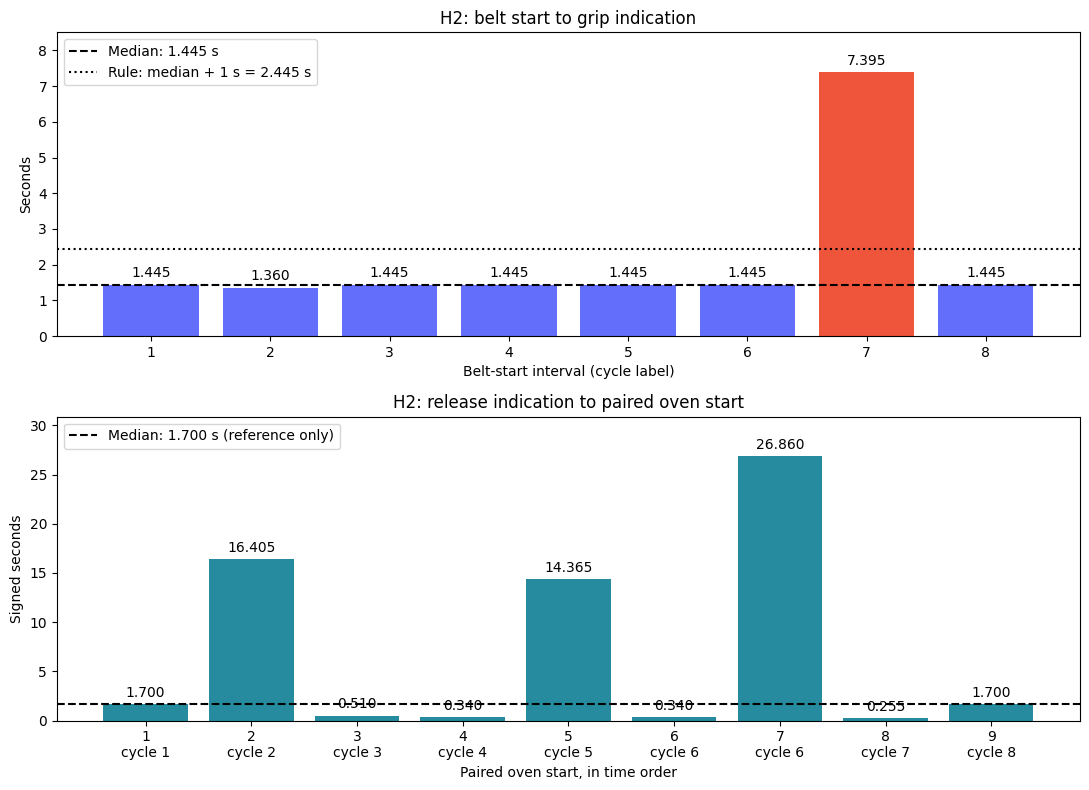

In [27]:
# H2 plot
import matplotlib.pyplot as plt  # plotting library

med_wait = robot["belt_start_to_grip_s"].median()  # panel 1 reference
med_oven = oven_in["seconds_after_release"].median()  # panel 2 reference

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8))  # two panels

# Panel 1: belt start to grip, red when 1 s above the median.
b1 = ax1.bar(  # one bar per belt-start interval
    robot["cycle"], robot["belt_start_to_grip_s"],
    color=["#EF553B" if w else "#636efa"  # red if over the rule
           for w in robot["wait_over_1s"]],
)
ax1.bar_label(b1, fmt="%.3f", padding=3)  # value on each bar
ax1.axhline(  # median line
    med_wait, color="black", linestyle="--",
    label=f"Median: {med_wait:.3f} s",
)
ax1.axhline(  # rule line: median + 1 s
    med_wait + 1.0, color="black", linestyle=":",
    label=f"Rule: median + 1 s = {med_wait + 1.0:.3f} s",
)
ax1.set_title("H2: belt start to grip indication")  # panel title
ax1.set_xticks(robot["cycle"])  # one tick per interval
ax1.set_xlabel("Belt-start interval (cycle label)")  # x-axis title
ax1.set_ylabel("Seconds")  # y-axis title
ax1.margins(y=0.15)  # room for the value labels
ax1.legend()  # show the line labels

# Panel 2: release to the paired oven start.
pair_numbers = range(1, len(oven_in) + 1)  # 1 ... number of pairs
b2 = ax2.bar(  # one bar per pair
    pair_numbers, oven_in["seconds_after_release"],
    color="#268b9e",
)
ax2.bar_label(b2, fmt="%.3f", padding=3)  # value on each bar
ax2.axhline(  # median line, reference only
    med_oven, color="black", linestyle="--",
    label=f"Median: {med_oven:.3f} s (reference only)",
)
ax2.axhline(0, color="grey", linewidth=0.7)  # zero line
ax2.set_xticks(pair_numbers)  # one tick per pair
ax2.set_xticklabels([  # pair number and its oven cycle
    f"{i}\ncycle {c}"
    for i, c in enumerate(oven_in["oven_cycle"], 1)
])
ax2.set_title("H2: release indication to paired oven start")  # title
ax2.set_xlabel("Paired oven start, in time order")  # x-axis title
ax2.set_ylabel("Signed seconds")  # y-axis title
ax2.margins(y=0.15)  # room for the value labels
ax2.legend()  # show the line label

fig.tight_layout()  # avoid overlapping text
plt.show()  # draw the figure


**What:**
- Plot both H2 parts in one figure with two panels
- Panel 1: belt start to grip indication for each belt-start interval, with the median (dashed) and the rule median + 1 s (dotted). Red bars are over the rule
- Panel 2: time from release to the paired oven start, with the median as a reference line only

**Why:**
- The bars show at once which interval or pair is far from the usual value
- The numbers on the bars let us read the exact values for the report

**Output:**
- Panel 1: 8 bars, median 1.445 s, rule line at 2.445 s, only cycle 7 (7.395 s) is red
- Panel 2: 9 bars, median 1.700 s, with 16.405 s, 14.365 s and 26.860 s clearly above the others

**Next:** H3, the gaps between pusher events

### H3: short pauses increase the time between completed parts

We use the start of the pusher outputs A0.2, A0.3 and A0.4 (white, red, blue) as time marks and measure the gap between consecutive marks. A gap counts as long if it is at least 1.25 times the median gap. For every gap we also report how much stop-indicator time lies inside it.

A pusher activation is not yet verified as one completed part, so we read the result as a pattern in the timing and not as a measured production time.

In [28]:
completion_rows = []  # one row per pusher activation
for colour, column in [  # the three pusher outputs
    ("white", "A0.2"),
    ("red", "A0.3"),
    ("blue", "A0.4"),
]:
    for start, end in pulses(merged, column):  # every activation
        completion_rows.append((start, colour))  # only the start counts

done = pd.DataFrame(  # all pusher events in time order
    sorted(completion_rows), columns=["time_s", "colour"]
)
done["gap_s"] = done["time_s"].diff()  # gap to the previous event

stop_in_gap = []  # stop-indicator seconds inside each gap
for previous, current in zip(done["time_s"].shift(), done["time_s"]):
    if pd.isna(previous):  # the first event has no gap
        stop_in_gap.append(float("nan"))  # no value for it
        continue

    overlap_s = sum(  # add up the overlap with every stop interval
        max(
            0.0,
            min(current, stop.end_s) - max(previous, stop.start_s),
        )
        for stop in stops_observed.itertuples(index=False)
    )
    stop_in_gap.append(overlap_s)  # keep the value for this gap

done["stop_in_gap_s"] = stop_in_gap  # add it to the table

# H2 timing context, not a duration attributable to this gap.
oven_context = []  # longest release-to-oven time inside each gap
for previous, current in zip(done["time_s"].shift(), done["time_s"]):
    if pd.isna(previous):  # the first event has no gap
        oven_context.append(float("nan"))  # no value for it
        continue

    matching = oven_in.loc[  # oven starts inside this gap
        (oven_in["oven_in_s"] > previous)
        & (oven_in["oven_in_s"] <= current),
        "seconds_after_release",
    ]
    oven_context.append(  # longest one, or NaN if there is none
        matching.max() if not matching.empty else float("nan")
    )

done["max_release_to_oven_context_s"] = oven_context  # add to the table

gap_median_s = done["gap_s"].median()  # usual gap
done["long_gap"] = done["gap_s"] >= 1.25 * gap_median_s  # screening rule

print("Pusher events:", len(done))  # expect 10
print("Measured gaps:", done["gap_s"].notna().sum())  # expect 9
print("Median gap in seconds:", round(gap_median_s, 3))  # expect 45.73
print("Flagged long gaps:", int(done["long_gap"].sum()))  # expect 3
print(done.round(3).to_string(index=False))  # full table

Pusher events: 10
Measured gaps: 9
Median gap in seconds: 45.73
Flagged long gaps: 3
 time_s colour  gap_s  stop_in_gap_s  max_release_to_oven_context_s  long_gap
 29.495   blue    NaN            NaN                            NaN     False
 57.970    red 28.475          0.000                            NaN     False
129.625    red 71.655          0.000                         16.405      True
155.805   blue 26.180          0.000                            NaN     False
209.525   blue 53.720          0.000                          0.340     False
283.475  white 73.950          8.925                         14.365      True
329.205    red 45.730          0.000                          0.340     False
371.875  white 42.670          0.000                         26.860     False
408.255  white 36.380         10.455                            NaN     False
480.335  white 72.080         12.495                          1.700      True


**What:**
- H3: collect the start of every pusher activation (A0.2 white, A0.3 red, A0.4 blue) and sort them in time
- Calculate the gap to the previous pusher event
- For every gap, add up the stop-indicator time inside it (stops_observed from cell 6)
- Add the longest release-to-oven time of H2 inside the gap, as context only
- Mark a gap as long if it is at least 1.25 times the median gap

**Why:**
- The time between pusher events shows if the plant keeps its usual rhythm. We use them as marks of finished parts, but we have not verified that one activation is one completed part
- The stop time inside a gap tells if a stop indicator could be part of an explanation
- The H2 value is only context. It is not a duration that belongs to this gap
- 1.25 times the median is our chosen screening rule, as in H1

**Output:**
- Pusher events: 10, measured gaps: 9, median gap 45.730 s
- Flagged long gaps: 3
  - 129.625 s: gap 71.655 s, stop 0.000 s, H2 context 16.405 s
  - 283.475 s: gap 73.950 s, stop 8.925 s, H2 context 14.365 s
  - 480.335 s: gap 72.080 s, stop 12.495 s, H2 context 1.700 s
- A gap that is not flagged also holds stop time: 36.380 s at 408.255 s with 10.455 s

**Next:** plot the gaps and the stop time inside them

Pusher events: 10; gaps: 9; threshold: 57.162 s; flagged: 3


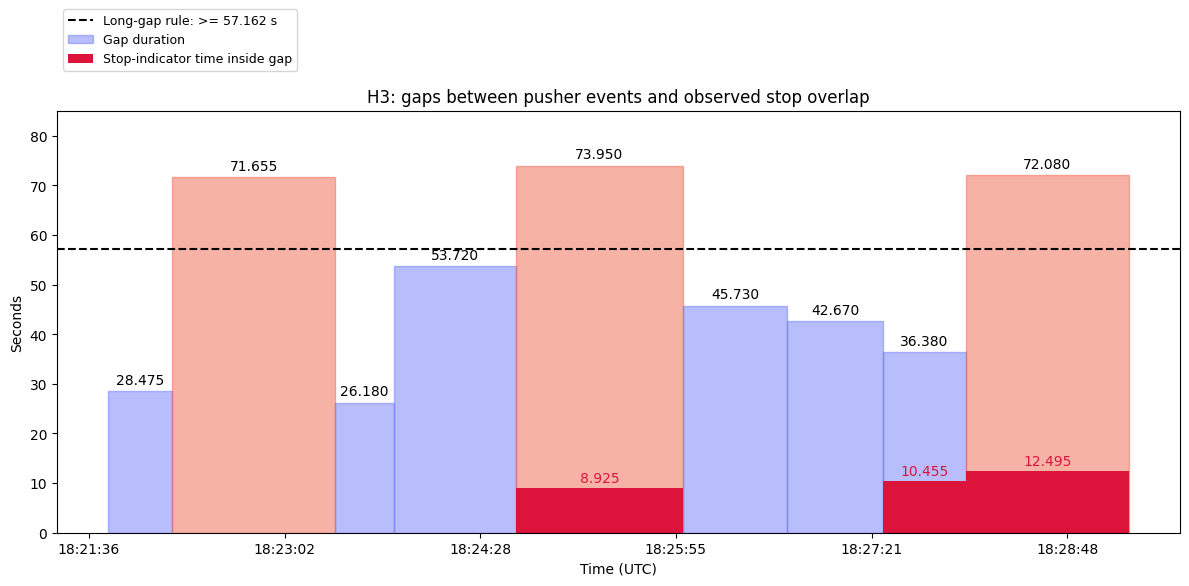

In [29]:
import pandas as pd  # tables
import matplotlib.dates as mdates  # time axis helpers
import matplotlib.pyplot as plt  # plotting library


def h3_pulses(df, column):  # ON-periods of one signal
    changes = df[column].eq(1).astype(int).diff()  # +1 start, -1 end
    starts = df.loc[changes.eq(1), "t_s"]  # rising edges
    ends = df.loc[changes.eq(-1), "t_s"]  # falling edges
    return [(s, ends[ends > s].iloc[0]) for s in starts  # first end after
            if not ends[ends > s].empty]  # only periods with an end


t = merged["t_s"]  # time axis in seconds
runs = []  # all stop-indicator intervals
# Stop indicators: curtain (A201.0 = 0) and screen (Visual.start = 0).
for active in [merged["A201.0"].eq(0), merged["Visual.start"].eq(0)]:
    changes = active.astype(int).diff()  # +1 start, -1 end
    starts = list(t[changes.eq(1)])  # rising edges
    ends = list(t[changes.eq(-1)])  # falling edges
    if active.iloc[0]:  # active in the first row: partial interval
        starts = [t.iloc[0]] + starts
    if active.iloc[-1]:  # active in the last row: partial interval
        ends = ends + [t.iloc[-1]]
    runs += list(zip(starts, ends))  # pair the edges

united = []  # combined intervals as [start, end]
for s, e in sorted(runs):  # in time order
    if united and s <= united[-1][1]:  # overlaps the last interval
        united[-1][1] = max(united[-1][1], e)  # extend it
    else:
        united.append([s, e])  # start a new interval

events = sorted(s for c in ["A0.2", "A0.3", "A0.4"]  # pusher starts
                for s, e in h3_pulses(merged, c))
rows = []  # one row per gap
for a, b in zip(events, events[1:]):  # consecutive pusher events
    stop_s = sum(max(0.0, min(b, e) - max(a, s)) for s, e in united)
    rows.append((a, b, b - a, stop_s))  # start, end, gap, stop time
g = pd.DataFrame(rows, columns=["a_s", "b_s", "gap_s", "stop_s"])  # table
thr = 1.25 * g["gap_s"].median()  # long-gap rule
g["flag"] = g["gap_s"] >= thr  # True for long gaps
print(f"Pusher events: {len(events)}; gaps: {len(g)}; "
      f"threshold: {thr:.3f} s; flagged: {g['flag'].sum()}")

base = merged["utc_time"].iloc[0]  # UTC time of t_s = 0
mid = mdates.date2num([  # middle of each gap on the time axis
    base + pd.Timedelta(seconds=(a + b) / 2)
    for a, b in zip(g["a_s"], g["b_s"])
])
widths = g["gap_s"] / 86400  # date axis counts in days
colors = ["#EF553B" if f else "#636efa" for f in g["flag"]]  # red if long

fig, ax = plt.subplots(figsize=(12, 6))  # one panel
b1 = ax.bar(  # gap durations
    mid, g["gap_s"], width=widths, color=colors,
    alpha=0.45, edgecolor=colors, label="Gap duration",
)
b2 = ax.bar(  # stop-indicator time inside each gap
    mid, g["stop_s"], width=widths, color="crimson",
    label="Stop-indicator time inside gap",
)
ax.bar_label(b1, fmt="%.3f", padding=3)  # value on each gap bar
ax.bar_label(  # value on each stop bar, none if zero
    b2,
    labels=[f"{v:.3f}" if v > 0 else "" for v in g["stop_s"]],
    padding=2, color="crimson",
)
ax.axhline(  # long-gap rule
    thr, color="black", linestyle="--",
    label=f"Long-gap rule: >= {thr:.3f} s",
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))  # clock
ax.set_title("H3: gaps between pusher events and observed stop overlap")
ax.set_xlabel("Time (UTC)")  # x-axis title
ax.set_ylabel("Seconds")  # y-axis title
ax.margins(y=0.15)  # room for the value labels
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.08), fontsize=9)  # above
fig.tight_layout()  # avoid overlapping text
plt.show()  # draw the figure

**What:**
- Plot the 9 gaps between pusher events as bars centred at the middle of each gap, as wide as the gap is long
- Draw the stop-indicator time inside each gap as a second bar and the long-gap rule as a dashed line

**Why:**
- The picture shows if the long gaps are the ones with stop time inside, and where in the recording they lie (UTC time axis)
- Red bars: gaps at or above the rule (1.25 times the median gap)

**Output:**
- Pusher events: 10; gaps: 9; threshold: 57.162 s; flagged: 3
- Figure: 3 red gaps (71.655 s, 73.950 s, 72.080 s). The stop bars (crimson) show 8.925 s, 10.455 s and 12.495 s inside gaps

**Next:** H4, which station carries the flagged extra time

### H4: one station causes more delay than the others

We look up the station of every flagged activation in the signal dictionary and add up the extra duration per station. We only count activations where the stop-indicator overlap is below half of the extra duration, so extra time that a stop indicator already covers is not credited to a station.

The sums can contain overlapping durations, so they are not unique downtime. The result tells us where to look first. It does not prove a bottleneck.

In [30]:
from pathlib import Path  # file paths

import openpyxl  # reads the Excel dictionary

dictionary_folder = Path(  # folder with the dictionary file
    ""
    "Raw_Data"
)
dictionary_files = sorted(dictionary_folder.glob("Variablen*.xlsx"))
if len(dictionary_files) != 1:  # stop if the file is not unique
    raise ValueError(
        f"Expected one dictionary file, found: {dictionary_files}"
    )

workbook = openpyxl.load_workbook(dictionary_files[0])  # open the file
siemens_stations = {  # Siemens: variable name -> station
    row[0]: row[3]  # first column is the name, fourth the station
    for row in workbook["Siemens"].iter_rows(
        min_row=2, values_only=True  # skip the header row
    )
    if row[0]  # skip empty rows
}
beckhoff_stations = {  # Beckhoff: variable name -> station
    row[0]: row[1]  # first column is the name, second the station
    for row in workbook["Beckhoff"].iter_rows(
        min_row=2, values_only=True  # skip the header row
    )
    if row[0]  # skip empty rows
}
workbook.close()  # close the file

station_analysis = slow_with_stops.copy()  # flagged activations
station_analysis["station"] = [  # look up the station of every signal
    (
        siemens_stations.get(row.signal)  # Siemens signal
        if row.plc == "Siemens"
        else beckhoff_stations.get(row.signal)  # Beckhoff signal
    )
    for row in station_analysis.itertuples(index=False)
]
station_analysis["station"] = (  # no station found -> "Unmapped"
    station_analysis["station"]
    .replace(r"^\s*$", pd.NA, regex=True)  # empty text counts as missing
    .fillna("Unmapped")  # label the missing ones
)

# Only activations with stop overlap below half of their extra time.
below = station_analysis.loc[
    ~station_analysis["overlap_at_least_half_extra"]
]
by_station = (  # sum the extra seconds per station
    below.groupby("station")
    .agg(
        summed_extra_s=("extra_s", "sum"),  # total extra time
        flagged_activations=("extra_s", "size"),  # number of activations
    )
    .sort_values("summed_extra_s", ascending=False)  # largest first
)

unknown = station_analysis.loc[  # signals without a station
    station_analysis["station"].eq("Unmapped"),
    ["plc", "signal"],
].drop_duplicates()

covered_extra_s = station_analysis.loc[  # extra time with stop overlap
    station_analysis["overlap_at_least_half_extra"], "extra_s"
].sum()
observed_stop_s = (  # total observed stop-indicator time
    stops_observed["end_s"] - stops_observed["start_s"]
).sum()

print("Flagged extra duration below the stop-overlap threshold:")
print(by_station.round(3).to_string())  # one row per station
print("\nUnmapped signals:")
print("None" if unknown.empty else unknown.to_string(index=False))
print(
    "\nSummed extra duration at/above the overlap threshold:",
    round(covered_extra_s, 3),  # expect 41.735
    "s",
)
print("Observed stop-indicator time:", round(observed_stop_s, 3), "s")

Flagged extra duration below the stop-overlap threshold:
                  summed_extra_s  flagged_activations
station                                              
Warehouse                 29.835                    6
Drilling station           6.205                    2

Unmapped signals:
None

Summed extra duration at/above the overlap threshold: 41.735 s
Observed stop-indicator time: 40.375 s


**What:**
- H4: read the Station column of the signal dictionary (Variablen*.xlsx, sheets Siemens and Beckhoff)
- Add the station to each of the 13 flagged activations, "Unmapped" if the dictionary has none
- Keep the activations whose stop overlap is below half of their extra duration (8 of 13) and add up their extra seconds per station

**Why:**
- We name equipment only through the signal dictionary, not by guessing from the signal names
- Extra time that a stop indicator already overlaps is not credited to a station, so only the activations without that cover count
- The file is found by pattern, and the cell stops with an error if not exactly one file matches

**Output:**
- Warehouse: 29.835 s summed extra over 6 flagged activations
- Drilling station: 6.205 s over 2 flagged activations
- Unmapped signals: none
- Summed extra duration at or above the overlap threshold: 41.735 s
- Observed stop-indicator time: 40.375 s. The two numbers differ, because activations can overlap each other in time, so the sums are not unique downtime

**Next:** plot the extra duration per station

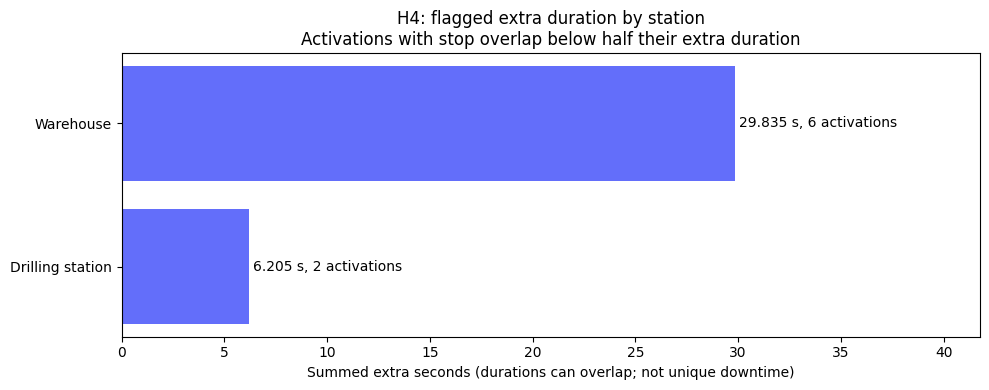

In [31]:
import matplotlib.pyplot as plt  # plotting library

plot_df = by_station.sort_values("summed_extra_s")  # largest bar on top

fig, ax = plt.subplots(figsize=(10, 4))  # one panel
bars = ax.barh(  # one horizontal bar per station
    plot_df.index, plot_df["summed_extra_s"],
    color="#636efa",
)
ax.bar_label(  # seconds and number of activations on each bar
    bars,
    labels=[
        f"{r.summed_extra_s:.3f} s, "
        f"{int(r.flagged_activations)} activations"
        for r in plot_df.itertuples()
    ],
    padding=3,
)
ax.set_title(  # title with the counting rule
    "H4: flagged extra duration by station\n"
    "Activations with stop overlap below half their extra duration"
)
ax.set_xlabel(  # warning that durations can overlap
    "Summed extra seconds (durations can overlap; not unique downtime)"
)
ax.margins(x=0.4)  # room for the labels
fig.tight_layout()  # avoid overlapping text
plt.show()  # draw the figure

**What:**
- Plot the summed extra duration per station as horizontal bars (stations where stop overlap is below half of the extra time)
- Write the seconds and the number of activations on each bar

**Why:**
- A bar chart shows the difference between the stations at once, and the labels keep the numbers readable for the report
- The x-axis title says that durations can overlap, so the bars are not unique downtime

**Output:**
- Figure with two bars: Warehouse 29.835 s, 6 activations and Drilling station 6.205 s, 2 activations

**Next:** write the conclusions for the four hypotheses

### Conclusions

The four checks below use the same numbering as our hypothesis list, H1 to H4.

**H1: Some machine steps take longer than usual.**
- Conclusion: supported for the measured output activations.
- 13 of 487 compared activations exceeded both thresholds: 25% above the median duration of their signal and at least 2 s extra.
- This identifies unusually long activations. It does not show faults or production loss.

**H2: Robot transfers cause waiting.**
- Conclusion: not confirmed.
- One belt-start-to-grip interval was unusually long: 7.395 s against a median of 1.445 s.
- Several release-to-oven times were also long (16.405 s, 14.365 s and 26.860 s against a median of 1.700 s). These timings do not show that the robot caused the waiting.

**H3: Short pauses increase the time between completed parts.**
- Conclusion: not confirmed, but long gaps were observed.
- 3 of 9 gaps between pusher events exceeded our threshold of 57.162 s.
- Two of the three contained stop-indicator time, but stop time also appeared in a gap that was not flagged.
- We have not yet verified that a pusher activation is a separate completed part.

**H4: One station causes more delay than the others.**
- Conclusion: the Warehouse carries more flagged extra duration, but we cannot confirm a cause.
- Among activations whose stop overlap is below half of their extra duration, the Warehouse has 29.835 s over 6 activations and the Drilling station has 6.205 s over 2.
- So the Warehouse is the first place to investigate. It is not a proven bottleneck.

**Overall:** we found unusual timing patterns and narrowed down where to investigate. We have not proven the causes and have not measured unique lost production time. These conclusions apply to this recording and to the thresholds we chose.